## Подготовка

Для python venv:
```bash
python3 -m venv data-analysis-venv
source .data-analysis-venv/bin/activate
pip install jupyter ipykernel ipywidgets
python3 -m ipykernel install --user --name=data-analysis-venv
```

Для conda venv (Anaconda / Miniconda должна быть установлена):
```bash
conda create -n data-analysis-venv python=3.13 -y
conda activate data-analysis-venv
pip install jupyter ipykernel ipywidgets
```

Далее установить необходимые пакеты:

* numpy
* scipy
* pandas
* scikit-learn
* tqdm
* ...

## Импорты пакетов и настройки

In [1]:
import warnings

warnings.filterwarnings("ignore")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [3]:
sns.set(style="whitegrid", palette="pastel")

In [4]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.interpolate import UnivariateSpline

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.decomposition import PCA

In [5]:
SEED = 0

## Загрузка и краткий анализ датасета

Загрузим датасет по ссылке:

In [6]:
!curl -L "https://drive.google.com/uc?export=download&id=1QRqfKa4DSz3PTk0fhpB854Rcl3wyRs1c" -o data_lollypops.dat

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  7810  100  7810    0     0   4047      0  0:00:01  0:00:01 --:--:-- 38663


Загрузим датасет. `read_csv` в pandas применим для открытия файлов `.dat`, для корректного чтения используем параметр, задающий разделитель: `sep=";"`.

In [7]:
data = pd.read_csv("data_lollypops.dat", sep=";")
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Проанализируем сводки по данным:

In [8]:
data.describe().round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000
mean,3.544,3.527,3.518,3.411,3.207,3.204,3.254,3.290,3.604,3.550,3.565
std,0.956,0.956,0.990,0.992,0.867,0.870,0.844,0.822,0.970,0.927,0.942
min,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000
25%,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
50%,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
75%,5.000,5.000,5.000,4.000,3.000,3.000,3.000,3.000,5.000,5.000,5.000
max,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000


In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


Таким образом, в датасете нет пропущенных значений и все значения валидные (нужного типа данных, без некорректностей и выбросов).

Посмотрим на распределение значений по каждому признаку:

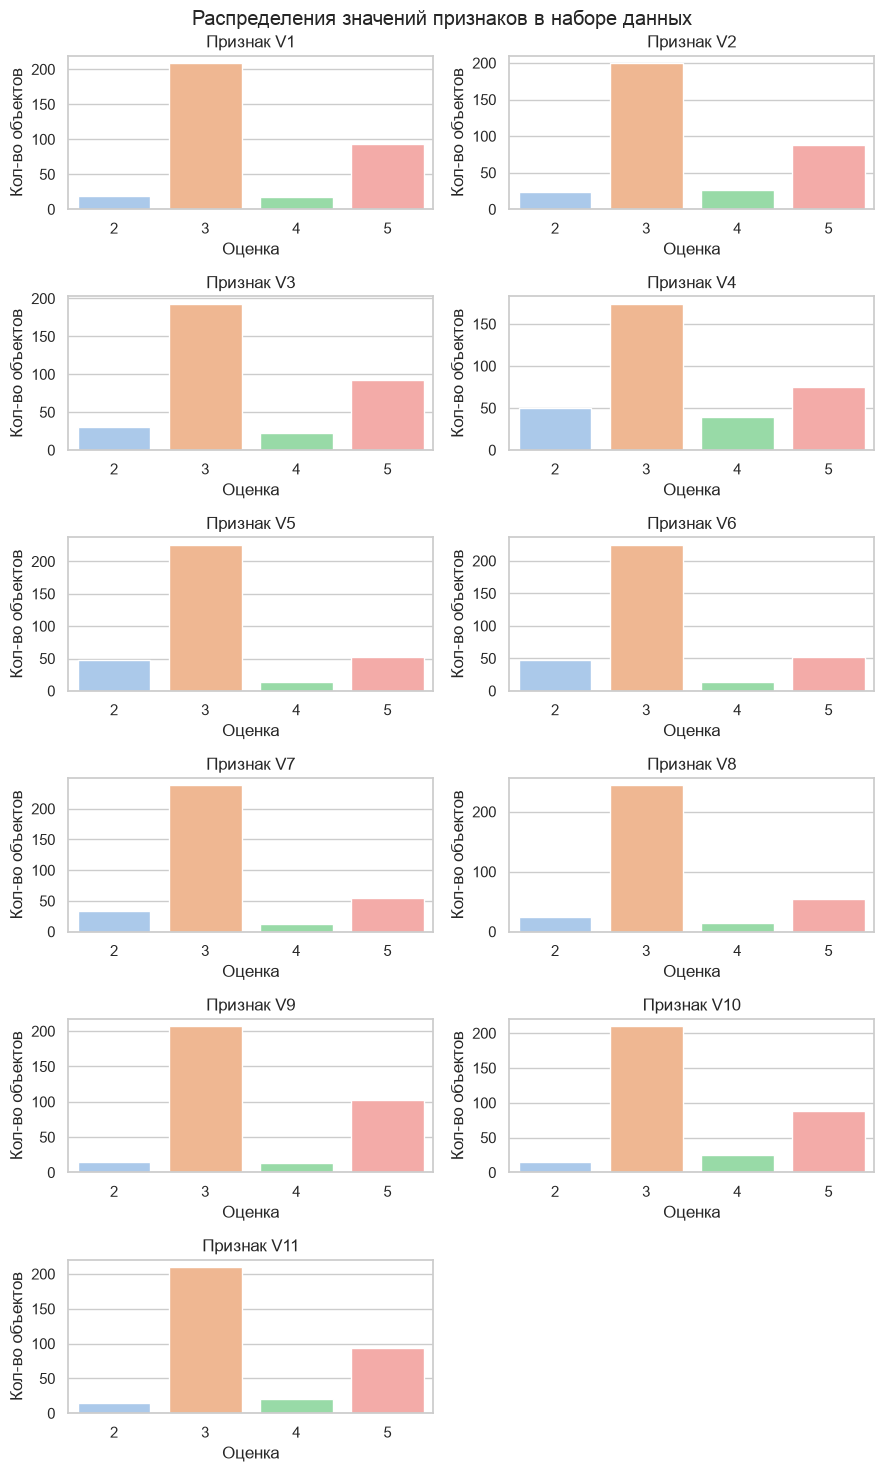

In [10]:
fig = plt.figure(figsize=(9, 15))

for idx, col in enumerate(data.columns):
    plt.subplot(6, 2, idx + 1)
    sns.countplot(data=data, x=col, palette="pastel")
    plt.title(f"Признак {col}")
    plt.xlabel("Оценка")
    plt.ylabel("Кол-во объектов")

fig.suptitle("Распределения значений признаков в наборе данных")

plt.tight_layout()
plt.show()

Из графиков выше и из кумулятивной статистики с помощью `describe()` видно, что среднее для всех признаков находится в диапазоне значений 3.2-3.6, а количество оценок 3 значительно превышает количество всех остальных оценок.

Схожесть распределений признаков наталкивает на мысль о том, что в данных есть одинаковые комбинации оценок. Построим диаграмму, чтобы увидеть, какое распределение уникальных комбинаций в датасете:

In [11]:
combs, counts = np.unique(data.to_numpy(), axis=0, return_counts=True)
unique_combs = {tuple(k): v for k, v in zip(combs, counts, strict=True)}

In [12]:
unique_combs_df = pd.DataFrame.from_dict(unique_combs, orient="index").reset_index()
unique_combs_df.columns = ["combination", "count"]
unique_combs_df["combination"] = unique_combs_df["combination"].apply(
    lambda x: ", ".join(map(str, x))
)
unique_combs_df = unique_combs_df.sort_values(by="count", ascending=False)
unique_combs_df.head()

,combination,count
21,"3, 3, 3, 3, 3, 3, 5, 5, 3, 3, 3",52
43,"5, 5, 5, 5, 3, 3, 3, 3, 3, 3, 3",49
19,"3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 5",49
25,"3, 3, 3, 3, 5, 5, 3, 3, 3, 3, 3",37
15,"3, 3, 3, 2, 2, 2, 2, 2, 5, 5, 5",15


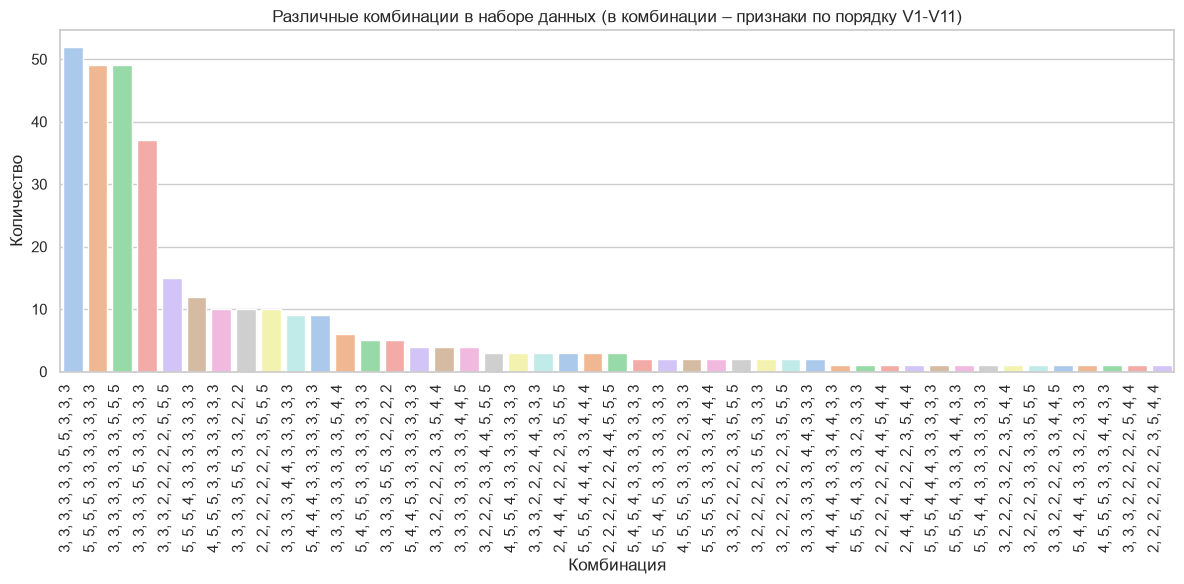

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=unique_combs_df, 
    x="combination", 
    y="count",
    palette="pastel"
)

plt.xticks(rotation=90, ha='right') 
plt.xlabel("Комбинация")
plt.ylabel("Количество")
plt.title("Различные комбинации в наборе данных (в комбинации – признаки по порядку V1-V11)")

plt.tight_layout()
plt.show()

Таким образом, мы видим, что комбинации с большинством троек преобладают – количество одинаковых комбинаций (с сохранением порядка признаков) может доходить до 50.

## Иерархическая кластеризация

Проведем кластеризацию с помощью построения иерархического дерева, показывающего разные уровни детализации при разделении данных на кластеры.

In [14]:
lnkg = linkage(data, method="ward")  # построение иерархических связей, использован метод Варда (Уорда)

Метод Варда используется здесь как один из часто используемых методов построения аггломеративной иерархии кластеров – он более универсальный, чем остальные, так как строит более равномерные кластеры, что повышает интерпретируемость. Использует минимизацию прироста суммы квадратов расстояний от каждой точки до центроида соответствующего кластера.

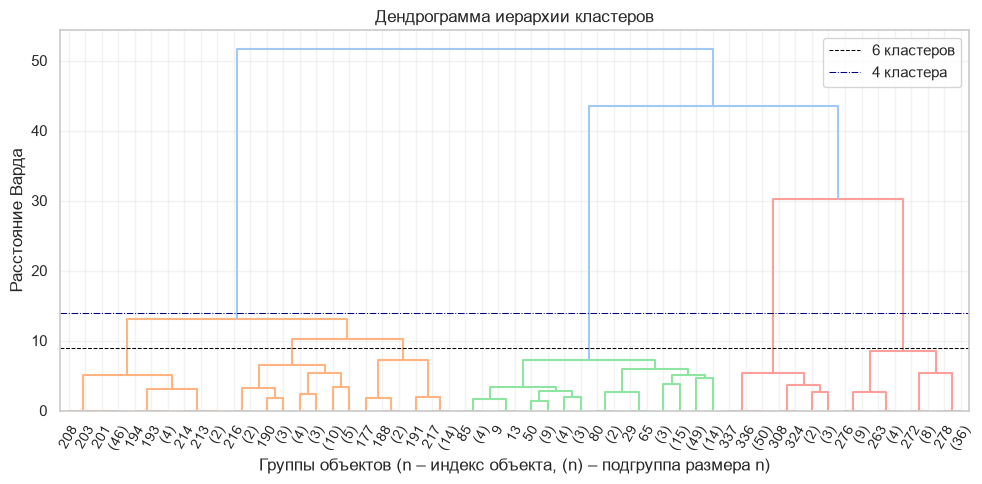

In [15]:
plt.figure(figsize=(10, 5))

dendrogram(
    lnkg, 
    truncate_mode="level", 
    p=5,
    leaf_rotation=60, 
    leaf_font_size=10
)
plt.axhline(9, lw=0.75, c="black", ls="--", label="6 кластеров")
plt.axhline(14, lw=0.75, c="navy", ls="-.", label="4 кластера")

plt.xlabel("Группы объектов (n – индекс объекта, (n) – подгруппа размера n)")
plt.ylabel("Расстояние Варда")
plt.title("Дендрограмма иерархии кластеров")
plt.grid(True, alpha=0.25)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

На дендрограмме выше можно видеть разные уровни разделения на кластеры. Горизонтальные прямые $y = d$ показывают количество кластеров при пороге разделения по расстоянию Варда, равному $d$. 

Так, при примерно $d \in [13, 30]$ получаем разделение на 4 кластера, при примерно $d \in [9, 10]$ – на 6 кластеров.

Можно отметить следующее – разделение на первые (по иерархии) 5-6 кластеров довольно уверенное, то есть дальнейшее деление происходит на более близких расстояниях. Значит, можно предположить, что примерно 6 кластеров достаточно удалены друг от друга, в то время как дальнейшее деление предусматривает сильно более близкие друг к другу группы точек.

Некоторый околобазовый эвристический метод на основе второй производной для иерархической кластеризации дает аналогичное рассуждениям выше количество кластеров, которое можно считать оптимальным:

In [16]:
def define_optim_cluster_number(
    linkage_matrix: np.ndarray,
    window_trsh: float = 0.05,
    window_size_limits: tuple[int] = (3, 25)
) -> int:
    """
    Function for defining the optimal number of clusters using the custom method of .

    Args:
        linkage_matrix (np.ndarray): Built linkage matrix (with 'ward' method by default).
        window_trsh (float): Threshold for determining the sliding window size. Default is 0.05.
        window_size_limits (tuple[int]): Tuple containing the minimum and maximum limits for the sliding window size. Default is (3, 25).

    Returns
        (int) Optimal number of clusters.
    """
    window_min, window_max = window_size_limits
    window = max(window_min, min(window_max, int(window_trsh * linkage_matrix.shape[0])))
    distances = np.sort(linkage_matrix[:, 2])  # distances between merging clusters
    smoothed_dists = np.convolve(distances, np.ones(window) / window, mode="valid")
    deriv = np.diff(smoothed_dists, n=2)
    # euristic shift from derivative peak idx
    deriv_elbow_idx = np.argmax(deriv) + window // 3 + 1
    threshold = distances[deriv_elbow_idx]
    labels = fcluster(linkage_matrix, t=threshold, criterion="distance")
    n_clusters = len(np.unique(labels))

    return threshold, n_clusters

In [17]:
trsh, n = define_optim_cluster_number(lnkg, 0.01, (3, 25))
print(f"Трешхолд отсечения по расстоянию Варда: {trsh:.6f}\nОптимальное кол-во кластеров: {n}")

Трешхолд отсечения по расстоянию Варда: 10.216433
Оптимальное кол-во кластеров: 5


Выполним аггломеративную кластеризацию с определенным ранее числом кластеров. Для построения визуального представления на 2D-графике воспользуемся методов главных компонент (PCA).

In [18]:
aggclust = AgglomerativeClustering(n_clusters=n, linkage="ward")
agg_pred = aggclust.fit_predict(data)

In [19]:
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data)

In [20]:
agg_centroids = np.array([data_pca[agg_pred == i].mean(axis=0) for i in range(n)])

In [21]:
COLORS = [
    "navy",
    "orange",
    "green",
    "red",
    "purple",
    "gold",
    "crimson",
    "lime",
    "skyblue",
    "pink",
    "blue",
    "brown",
    "gray",
    "teal",
    "yellow",
    "darkred"
]

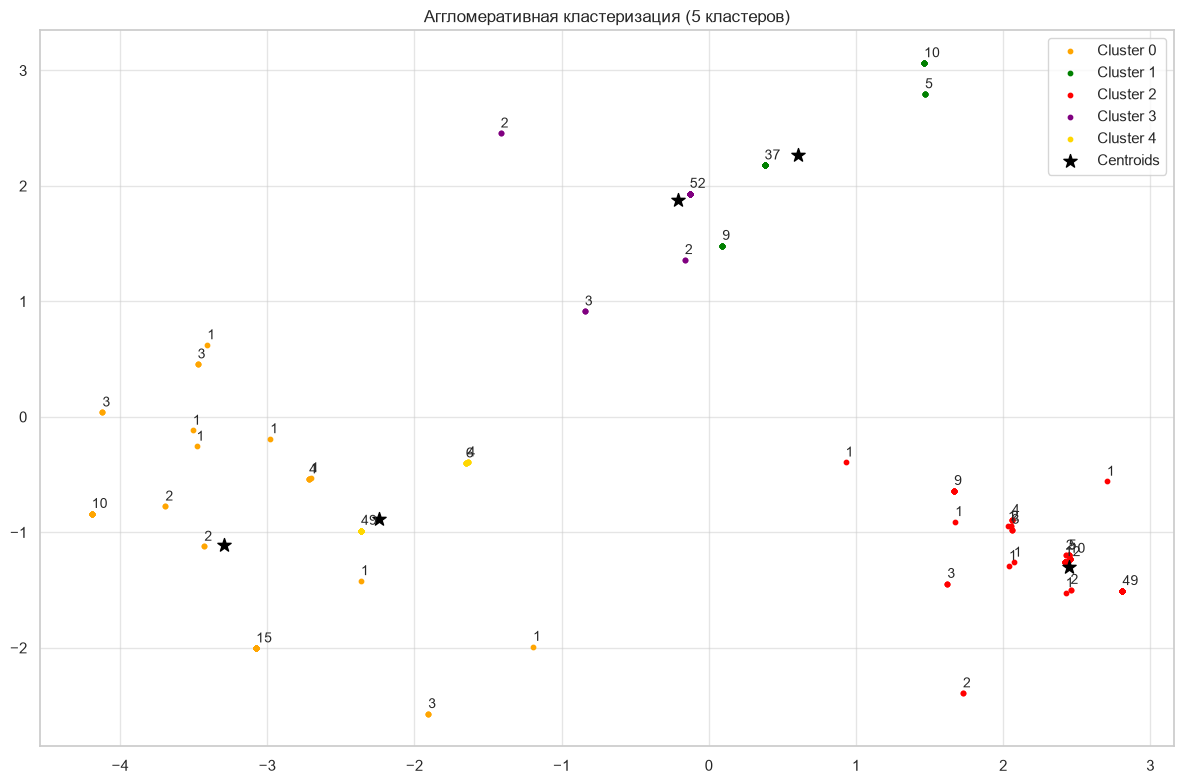

In [22]:
plt.figure(figsize=(12, 8))

for label in np.unique(agg_pred):
    _pts = data_pca[agg_pred == label]
    _unique_pts = np.unique(_pts, axis=0)
    plt.scatter(_pts[:, 0], _pts[:, 1], c=COLORS[label + 1], s=10, label=f"Cluster {label}")
    for pt in _unique_pts:
        plt.annotate(
            f"{len([goal for goal in _pts if np.array_equal(goal, pt)])}", 
            pt,
            (pt[0], pt[1] + 0.05),
            size=10
        )

plt.scatter(agg_centroids[:, 0], agg_centroids[:, 1], marker="*", c="black", s=100, label="Centroids")

plt.title("Аггломеративная кластеризация (5 кластеров)")
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Видно, что кластеры достаточно объяснимые, хотя сжатие до двух компонент из 11 не представляет реальной картины. Для большей интерпретируемости добавил к каждой точке аннотацию, обозначающую, сколько таких точек находится в этой координате на 2D-проекции.

Построим профили кластеров, чтобы проанализировать разделимость признаков, соответствующую найденным кластерам:

In [23]:
data_clusters_agg5 = data.copy()
data_clusters_agg5["Cluster"] = agg_pred
clusters_agg5_profiles = data_clusters_agg5.groupby("Cluster").mean()

clusters_agg5_profiles.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
0,2.612,2.633,2.490,2.163,2.143,2.082,2.449,2.816,4.980,4.796,4.816
1,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754
2,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045
3,3.000,2.966,2.966,2.915,2.915,2.949,4.915,4.915,3.000,3.000,3.000
4,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,4.932,4.831,4.898


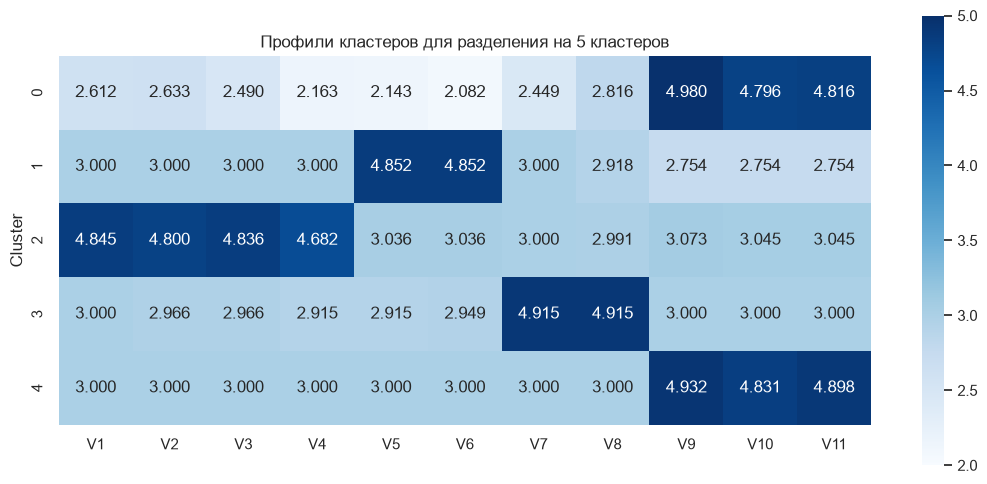

In [24]:
plt.figure(figsize=(11, 5))

sns.heatmap(
    clusters_agg5_profiles,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=2,
    vmax=5,
    square=True
)

plt.title("Профили кластеров для разделения на 5 кластеров")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Профилизация показывает, что кластер 2 соответствует признакам V1-V4 (качество жизни, удобство), кластер 1 – признакам V5-V6 (заменитель сладкого), кластер 3 – признакам V7-V8 (концентрация внимания), кластеры 0, 4 – признакам V9-V11 (лечебные цели). При этом видно, что лечебным целям соответствуют 2 кластера, и они достаточно близки по профилям. Кластер 4 соответствует в среднем более высоким оценкам.

Проделаем то же действие для четырех кластеров для наглядности:

In [25]:
aggclust2 = AgglomerativeClustering(n_clusters=4, linkage="ward")
agg_pred2 = aggclust2.fit_predict(data)

In [26]:
agg_centroids2 = np.array([data_pca[agg_pred2 == i].mean(axis=0) for i in range(4)])

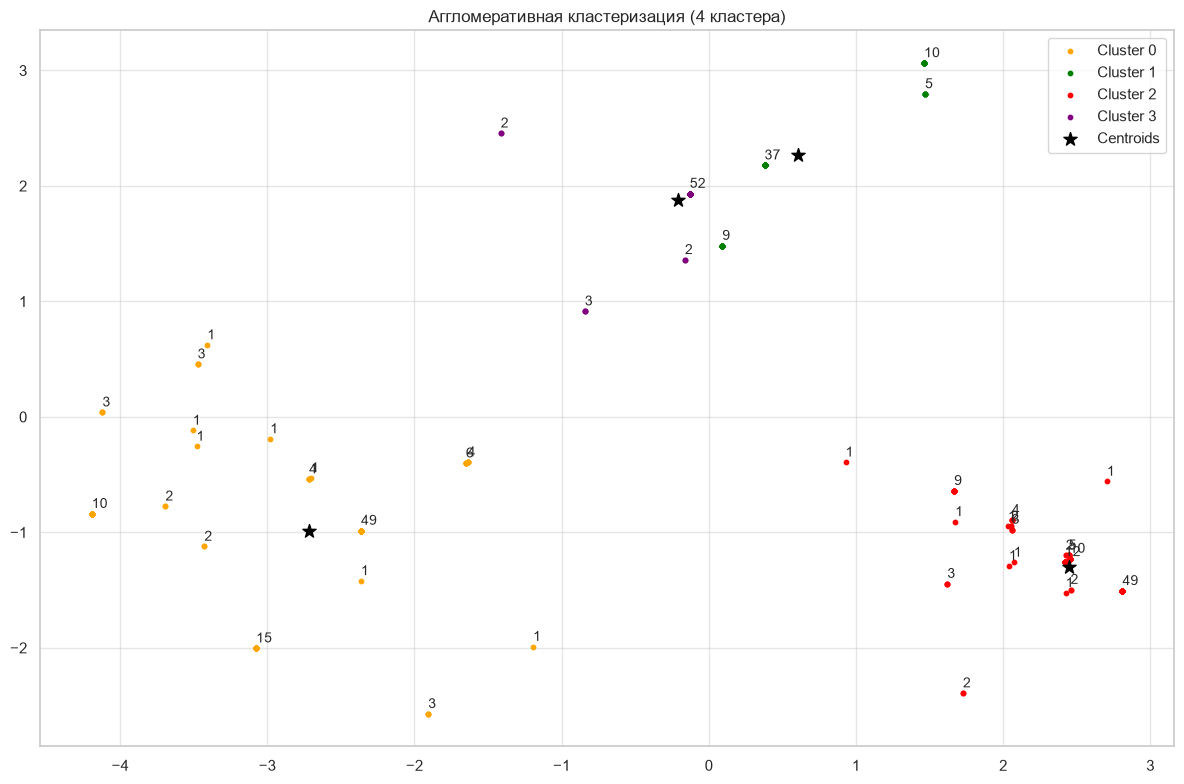

In [27]:
plt.figure(figsize=(12, 8))

for label in np.unique(agg_pred2):
    _pts = data_pca[agg_pred2 == label]
    _unique_pts = np.unique(_pts, axis=0)
    plt.scatter(_pts[:, 0], _pts[:, 1], c=COLORS[label + 1], s=10, label=f"Cluster {label}")
    for pt in _unique_pts:
        plt.annotate(
            f"{len([goal for goal in _pts if np.array_equal(goal, pt)])}", 
            pt,
            (pt[0], pt[1] + 0.05),
            size=10
        )

plt.scatter(agg_centroids2[:, 0], agg_centroids2[:, 1], marker="*", c="black", s=100, label="Centroids")

plt.title("Аггломеративная кластеризация (4 кластера)")
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Четкость кластеров подтверждает вывод, сделанный ранее из дендрограммы – 4-6 кластеров наиболее разделимы визуально.

Аналогично построим профили кластеров:

In [28]:
data_clusters_agg4 = data.copy()
data_clusters_agg4["Cluster"] = agg_pred2
clusters_agg4_profiles = data_clusters_agg4.groupby("Cluster").mean()

clusters_agg4_profiles.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
0,2.824,2.833,2.769,2.620,2.611,2.583,2.750,2.917,4.954,4.815,4.861
1,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754
2,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045
3,3.000,2.966,2.966,2.915,2.915,2.949,4.915,4.915,3.000,3.000,3.000


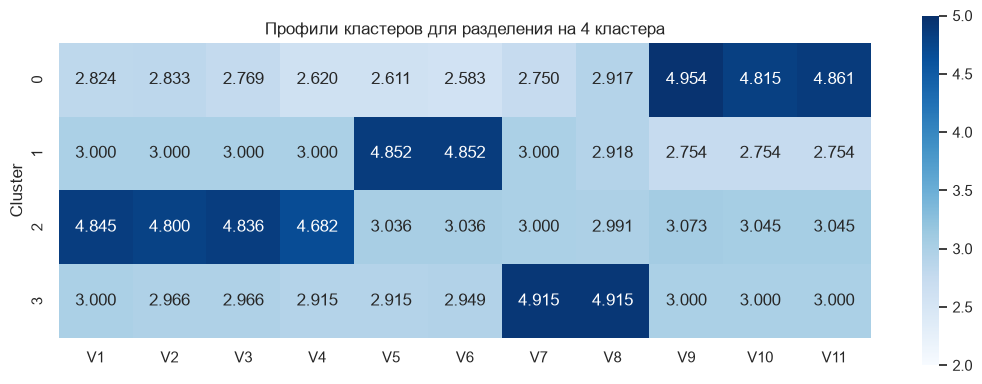

In [29]:
plt.figure(figsize=(11, 4))

sns.heatmap(
    clusters_agg4_profiles,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=2,
    vmax=5,
    square=True
)

plt.title("Профили кластеров для разделения на 4 кластера")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Деление на 4 кластера, как было сказано ранее, более четкое – профилизация более явная, разделение на цели более четкое.

## Кластеризация методом $k$-средних

Выполним кластеризацию методом k-средних. Для определения оптимального количества кластеров снова воспользуемся некоторым методом – автоматической эвристической реализацией метода локтя с помощью сплайн-интерполяции.

In [30]:
def get_kmeans_inertias(max_num_clusters: int, seed: int = SEED) -> list[float]:
    inertias = list()
    for cluster_num in tqdm(range(1, max_num_clusters + 1), desc="KMeans Exps"):
        _kmeans = KMeans(
            n_clusters=cluster_num,
            init="k-means++",
            n_init=15,
            random_state=seed,
        )
        _kmeans.fit(data)
        inertias.append(_kmeans.inertia_)
    return inertias

In [31]:
inertias = get_kmeans_inertias(max_num_clusters=15)

KMeans Exps:   0%|          | 0/15 [00:00<?, ?it/s]

KMeans Exps: 100%|██████████| 15/15 [00:00<00:00, 114.49it/s]


In [32]:
def find_optim_cluster_number(
    inertias, trsh: float = 0.325, min_inertia_trsh: float = 0.05
) -> int:
    """
    Algorithm for automatic number of clusters determination using elbow method.

    Args:
        inertias (list[int]): List of inertias from KMeans clustering.
        trsh (float): Threshold for separate inertias graph stable descending and fluctuations intervals.
            Defaults to 0.325.
        min_inertia_trsh (float): Minimal inertia value threshold for determining the end of the fluctuation or
            descending interval. Defaults to 0.05.

    Returns
        (int): Number of clusters determined by the elbow method.
    """
    inertias_norm = (
        (inertias - np.min(inertias))
        / (np.max(inertias) - np.min(inertias))
        * len(inertias)
    )
    x = np.arange(1, len(inertias_norm) + 1)

    weights = np.linspace(0, len(inertias), len(inertias_norm))[::-1]
    spline = UnivariateSpline(x, inertias_norm, k=4, w=weights)
    x_new = np.linspace(x.min(), x.max(), 1000)
    y_new = spline(x_new)

    diffs = np.abs(np.diff(y_new)) / np.abs(np.diff(x_new))
    condition = (
        (diffs[1:] < trsh)
        & (diffs[:-1] > trsh)
        & (y_new[1:-1] / len(inertias) >= min_inertia_trsh)
    )
    elbows = x_new[np.where(condition)[0] + 1]
    elbow = int(elbows[-1])
    return elbows, elbow, inertias_norm, x_new, y_new

Для реализации метода используются инерции – суммы квадратов расстояний от каждой точки данных до центроида соответствующего ей кластера. Иными словами, мера компактности кластера – чем меньше инерция, тем плотнее и однороднее точки внутри каждого кластера.

In [33]:
_, elbow, inertias_norm, x_spline, y_spline = find_optim_cluster_number(inertias)

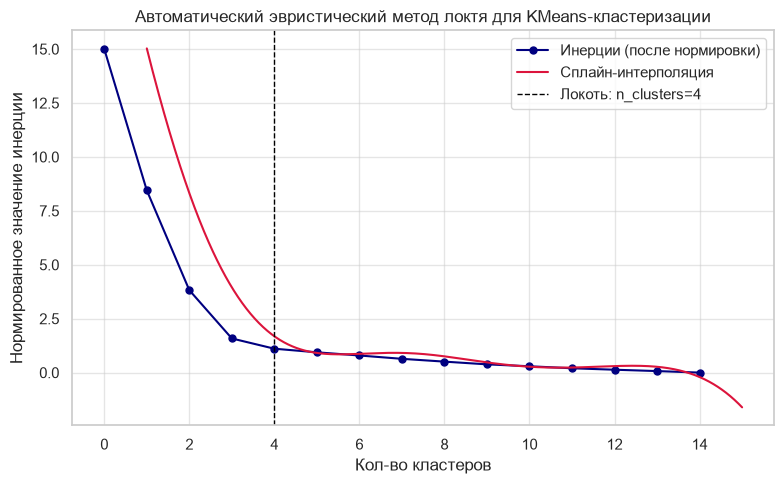

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(range(len(inertias)), inertias_norm, c="navy", marker="o", markersize=5, label="Инерции (после нормировки)")
plt.plot(x_spline, y_spline, c="crimson", label="Сплайн-интерполяция")
plt.axvline(elbow, lw=1, ls="--", c="black", label=f"Локоть: n_clusters={elbow}")

plt.title("Автоматический эвристический метод локтя для KMeans-кластеризации")
plt.xlabel("Кол-во кластеров")
plt.ylabel("Нормированное значение инерции")
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Реализуем кластеризацию с определенным количеством кластеров:

In [35]:
kmeansclust = KMeans(n_clusters=elbow, random_state=SEED)
kmeans_pred = kmeansclust.fit_predict(data)

In [36]:
kmeans_centroids = np.array([data_pca[kmeans_pred == i].mean(axis=0) for i in range(elbow)])

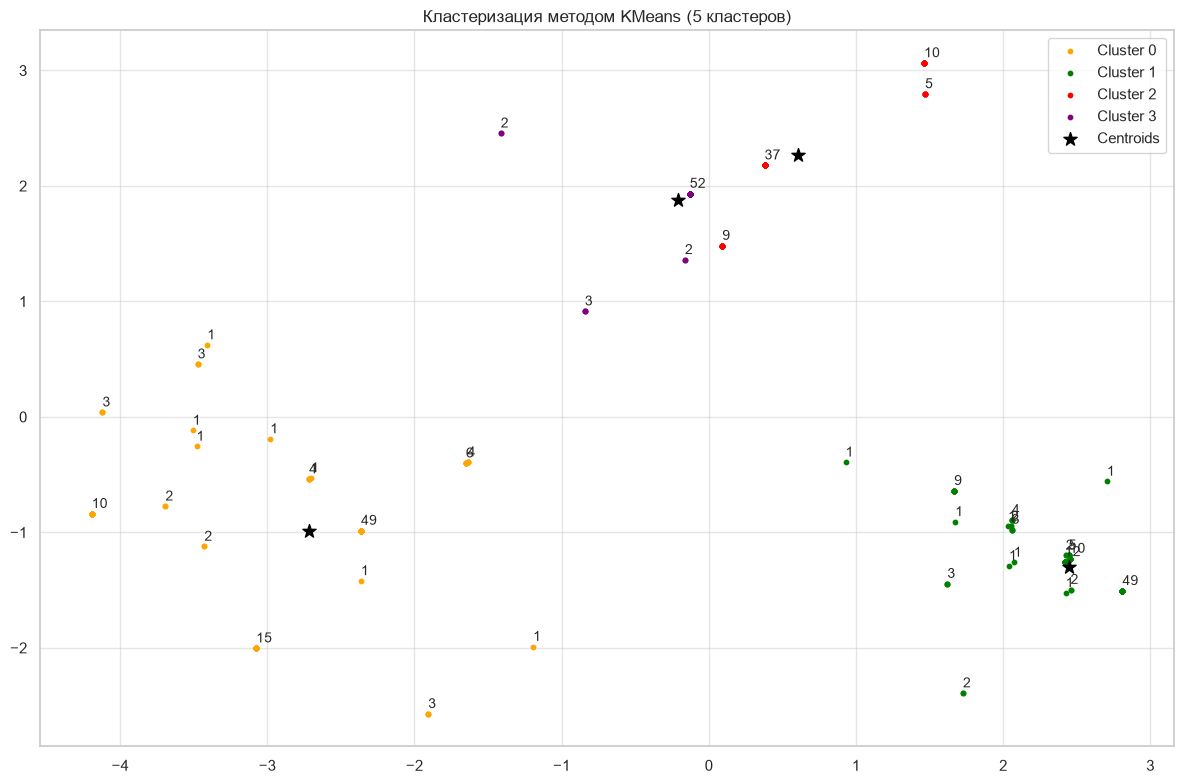

In [37]:
plt.figure(figsize=(12, 8))

for label in np.unique(kmeans_pred):
    _pts = data_pca[kmeans_pred == label]
    _unique_pts = np.unique(_pts, axis=0)
    plt.scatter(_pts[:, 0], _pts[:, 1], c=COLORS[label + 1], s=10, label=f"Cluster {label}")
    for pt in _unique_pts:
        plt.annotate(
            f"{len([goal for goal in _pts if np.array_equal(goal, pt)])}", 
            pt,
            (pt[0], pt[1] + 0.05),
            size=10
        )

plt.scatter(kmeans_centroids[:, 0], kmeans_centroids[:, 1], marker="*", c="black", s=100, label="Centroids")

plt.title("Кластеризация методом KMeans (5 кластеров)")
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Профилизация кластеров:

In [38]:
data_clusters_kmeans = data.copy()
data_clusters_kmeans["Cluster"] = kmeans_pred
clusters_kmeans_profiles = data_clusters_kmeans.groupby("Cluster").mean()

clusters_kmeans_profiles.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
0,2.824,2.833,2.769,2.620,2.611,2.583,2.750,2.917,4.954,4.815,4.861
1,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045
2,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754
3,3.000,2.966,2.966,2.915,2.915,2.949,4.915,4.915,3.000,3.000,3.000


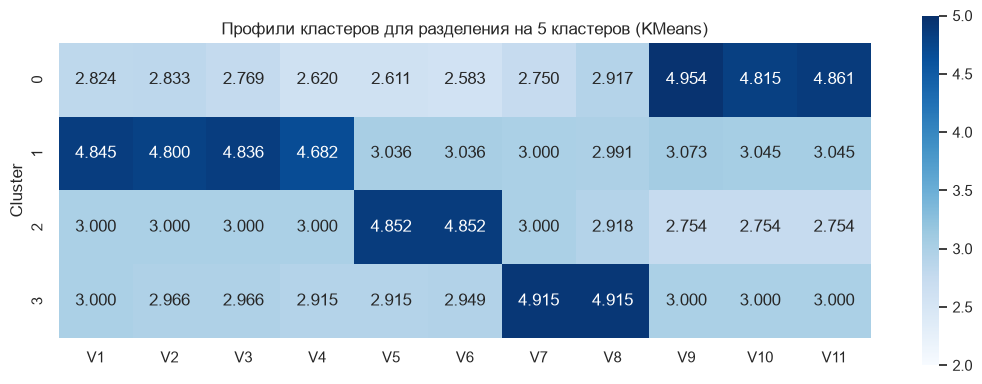

In [39]:
plt.figure(figsize=(11, 4))

sns.heatmap(
    clusters_kmeans_profiles,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=2,
    vmax=5,
    square=True
)

plt.title("Профили кластеров для разделения на 5 кластеров (KMeans)")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Вывод про профили кластеров здесь аналогичный.

## Кластеризация методом DBSCAN

Метод DBSCAN является методом плотностной кластеризации – он не требует изначально задавать число кластеров, а производит деление на основе плотности объектов. Удаленные от других объекты метод помечает как шум.

Стоит упомянуть и ограничения метода DBSCAN – чувствительность к параметрам $\varepsilon$ и **min_samples** и плохое масштабирование на кластеры разной плотности. Есть более устойчивое расширение этого метода – hierarchical DBSCAN (HDBSCAN), в котором необходимо задать только один параметр – минимальный размер кластера **min_cluster_size**.

In [40]:
dbscan = DBSCAN(eps=0.7, min_samples=7)

In [41]:
dbscan_pred = dbscan.fit_predict(data)

In [42]:
dbscan_centroids = np.array([data_pca[dbscan_pred == i].mean(axis=0) for i in np.unique(dbscan_pred) if i != -1])

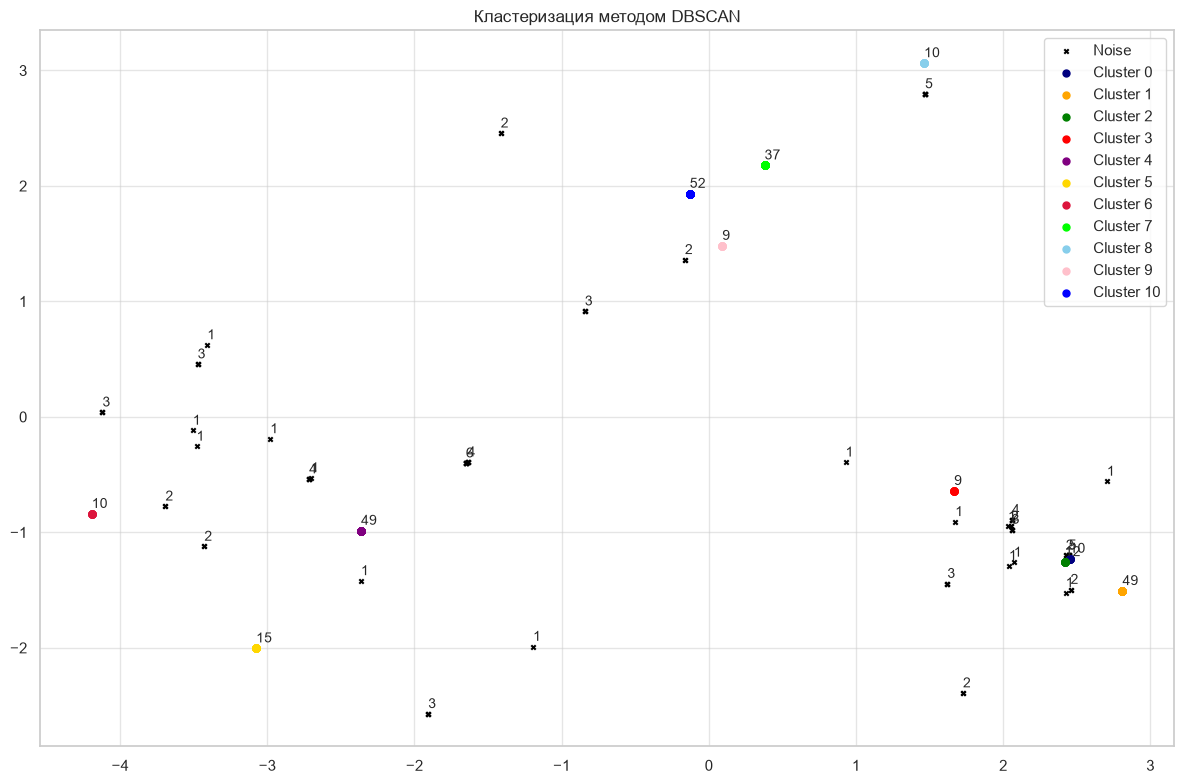

In [43]:
plt.figure(figsize=(12, 8))

for label in np.unique(dbscan_pred):
    _pts = data_pca[dbscan_pred == label]
    _unique_pts = np.unique(_pts, axis=0)
    plt.scatter(
        data_pca[dbscan_pred == label][:, 0], 
        data_pca[dbscan_pred == label][:, 1], 
        c=COLORS[label] if label != -1 else "black",
        marker="o" if label != -1 else "x", 
        s=10 if label == -1 else 25,
        label=f"Cluster {label}" if label != -1 else "Noise"
    )
    for pt in _unique_pts:
        plt.annotate(
            f"{len([goal for goal in _pts if np.array_equal(goal, pt)])}", 
            pt,
            (pt[0], pt[1] + 0.05),
            size=10
        )

plt.title("Кластеризация методом DBSCAN")
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Здесь явно видно, что DBSCAN выделяет скопления точек с наибольшей плотностью (повторяющиеся точки) в отдельные кластеры, в то время как единичные точки с очевидно меньшей плотностью отсекаются в шум.

Профилизация кластеров:

In [44]:
data_clusters_dbscan = data.copy()
data_clusters_dbscan["Cluster"] = dbscan_pred
clusters_dbscan_profiles = data_clusters_dbscan.groupby("Cluster").mean()

clusters_dbscan_profiles.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
-1,3.579,3.487,3.447,3.329,2.895,2.882,3.092,3.118,3.868,3.632,3.697
0,4.000,5.000,5.000,5.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
1,5.000,5.000,5.000,5.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
2,5.000,5.000,5.000,4.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
3,5.000,4.000,4.000,4.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
4,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,5.000,5.000,5.000
5,3.000,3.000,3.000,2.000,2.000,2.000,2.000,2.000,5.000,5.000,5.000
6,2.000,2.000,2.000,2.000,2.000,2.000,2.000,3.000,5.000,5.000,5.000
7,3.000,3.000,3.000,3.000,5.000,5.000,3.000,3.000,3.000,3.000,3.000


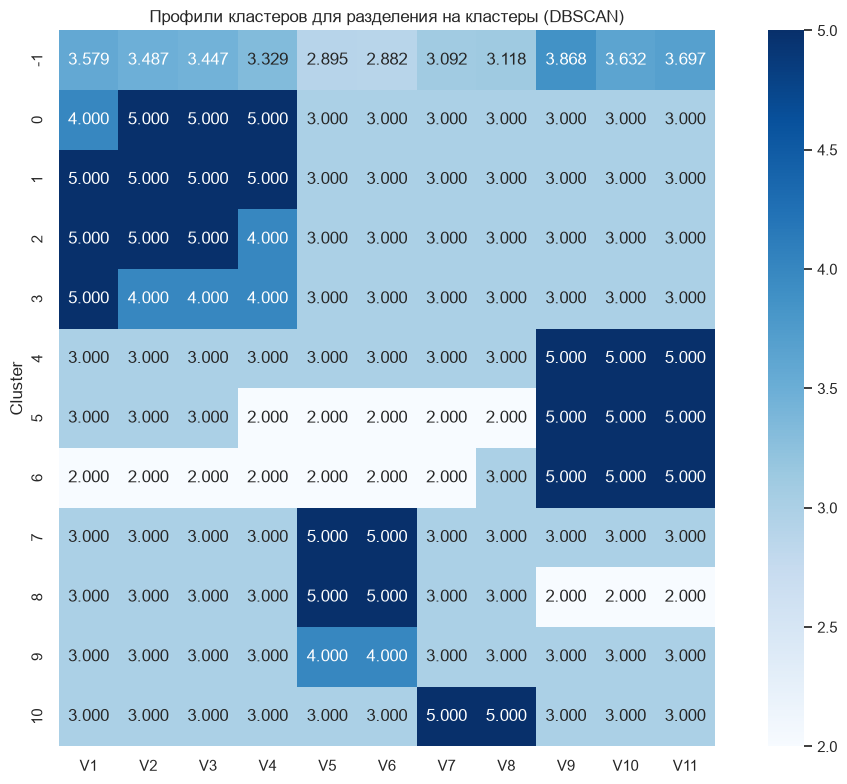

In [45]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    clusters_dbscan_profiles,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=2,
    vmax=5,
    square=True
)

plt.title("Профили кластеров для разделения на кластеры (DBSCAN)")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Проверим также метод HDBSCAN:

In [46]:
hdbscan = HDBSCAN(min_cluster_size=7)

In [47]:
hdbscan_pred = hdbscan.fit_predict(data)

In [48]:
hdbscan_centroids = np.array([data_pca[hdbscan_pred == i].mean(axis=0) for i in np.unique(hdbscan_pred) if i != -1])

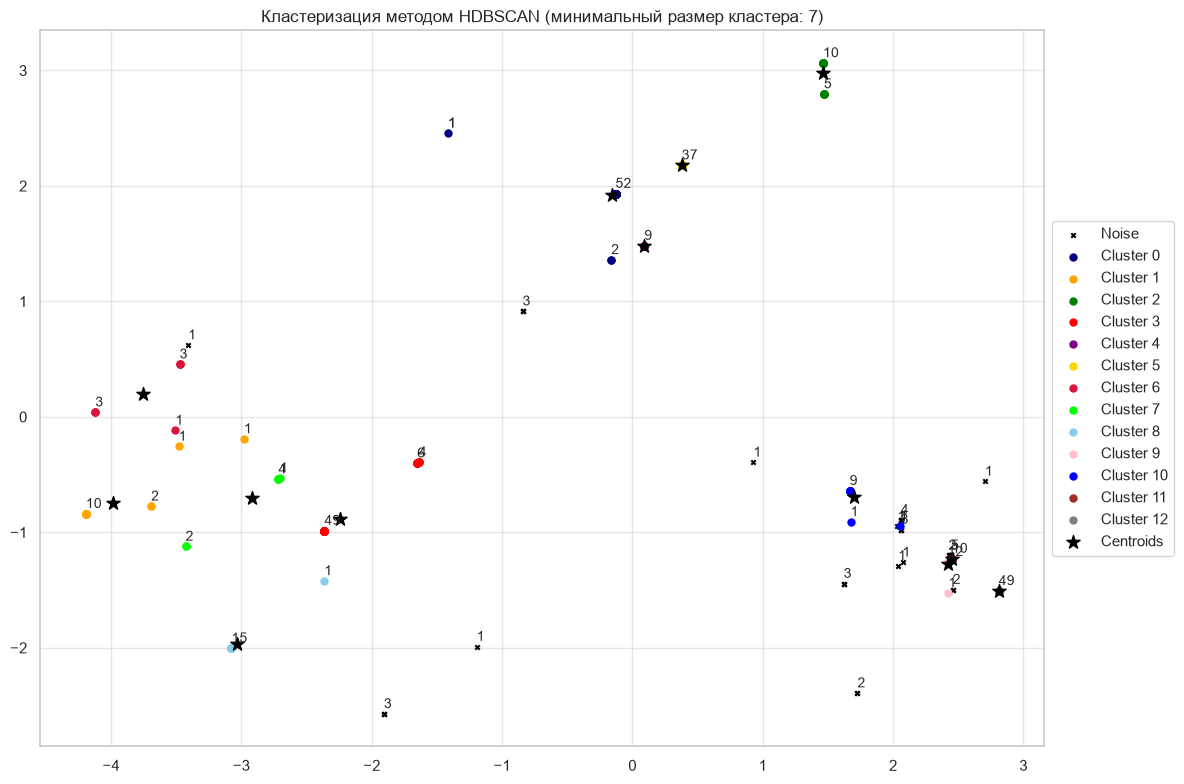

In [49]:
plt.figure(figsize=(12, 8))

for label in np.unique(hdbscan_pred):
    _pts = data_pca[hdbscan_pred == label]
    _unique_pts = np.unique(_pts, axis=0)
    plt.scatter(
        data_pca[hdbscan_pred == label][:, 0], 
        data_pca[hdbscan_pred == label][:, 1], 
        c=COLORS[label] if label != -1 else "black",
        marker="o" if label != -1 else "x", 
        s=10 if label == -1 else 25,
        label=f"Cluster {label}" if label != -1 else "Noise"
    )
    for pt in _unique_pts:
        plt.annotate(
            f"{len([goal for goal in _pts if np.array_equal(goal, pt)])}", 
            pt,
            (pt[0], pt[1] + 0.05),
            size=10
        )

plt.scatter(hdbscan_centroids[:, 0], hdbscan_centroids[:, 1], marker="*", c="black", s=100, label="Centroids")

plt.title("Кластеризация методом HDBSCAN (минимальный размер кластера: 7)")
plt.grid(True, alpha=0.5)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

Здесь мы видим похожу картину, но с лучшим разделением на кластеры – есть и единичные зоны (в кластере одна точка 2D-проекции), и объединенные, но также есть и шум – отдаленные точки с малым количеством точек в полной размерности.

Профилизация кластеров:

In [50]:
data_clusters_hdbscan = data.copy()
data_clusters_hdbscan["Cluster"] = hdbscan_pred
clusters_hdbscan_profiles = data_clusters_hdbscan.groupby("Cluster").mean()

clusters_hdbscan_profiles.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Cluster,,,,,,,,,,,
-1,4.167,4.250,4.333,4.167,2.861,2.889,3.056,3.194,3.500,3.361,3.361
0,3.000,2.982,2.982,2.982,2.982,3.000,4.964,4.964,3.000,3.000,3.000
1,2.214,2.000,2.000,2.000,2.214,2.000,2.000,3.000,5.000,4.857,4.857
2,3.000,3.000,3.000,3.000,5.000,5.000,3.000,2.667,2.000,2.000,2.000
3,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,4.932,4.831,4.898
4,3.000,3.000,3.000,3.000,4.000,4.000,3.000,3.000,3.000,3.000,3.000
5,3.000,3.000,3.000,3.000,5.000,5.000,3.000,3.000,3.000,3.000,3.000
6,2.571,2.000,2.000,2.000,2.571,2.571,3.857,3.857,5.000,5.000,5.000
7,3.000,3.000,2.000,2.000,2.000,2.000,3.000,3.000,4.857,4.286,4.429


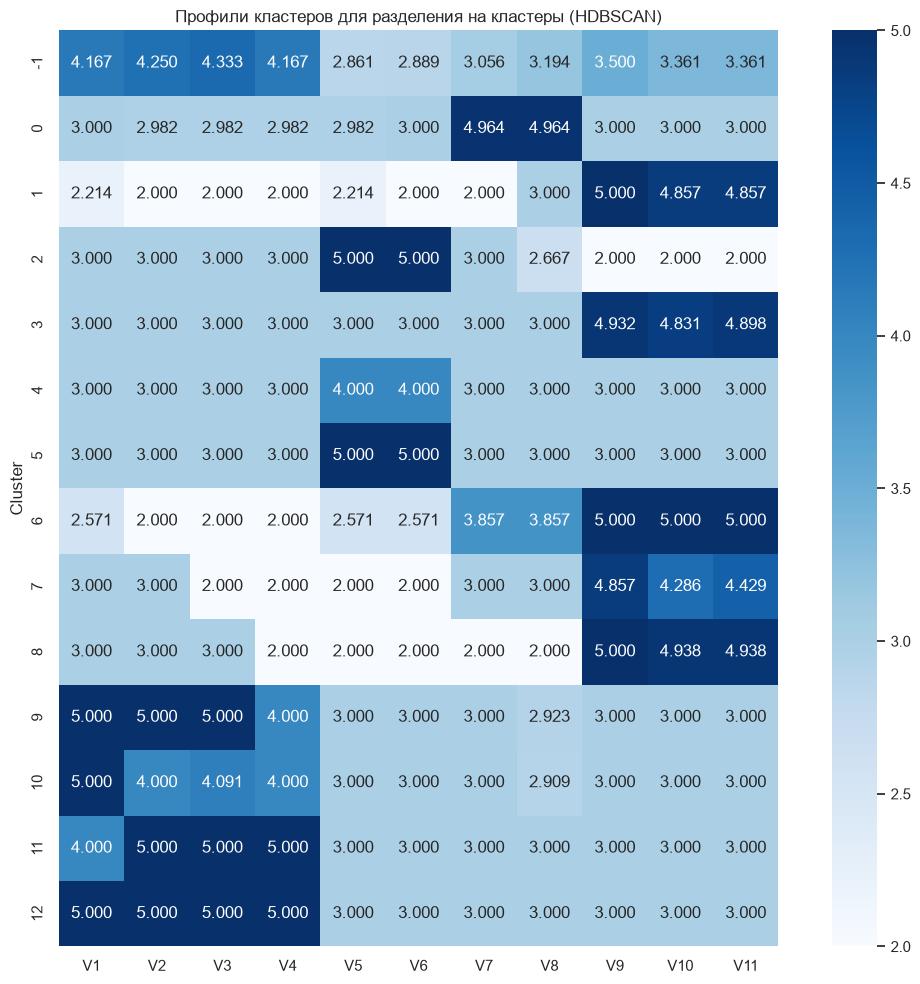

In [51]:
plt.figure(figsize=(11, 10))

sns.heatmap(
    clusters_hdbscan_profiles,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=2,
    vmax=5,
    square=True
)

plt.title("Профили кластеров для разделения на кластеры (HDBSCAN)")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

Для DBSCAN и HDBSCAN по профилизации кластеров видно, что смысловое разделение теряется – профили становятся неинтерпретируемыми в этом контексте, их разделение необъяснимо.

## Общие выводы

В ходе лабораторной работы был проведен кластерный анализ набора данных, состоящего из 338 объектов и 11 дискретных признаков (оценки от 2 до 5). Данные характеризуются сильным смещением к оценке **3** и наличием большого количества полностью идентичных объектов (дубликатов).

**1. Аггломеративная кластеризация (методом Варда) и KMeans:**
* Методы, основанные на минимизации внутрикластерной дисперсии, показали наилучшую структурированность данных. 
* Разработанные эвристические алгоритмы (анализ второй производной матрицы связей и сплайн-интерполяция инерции) позволили автоматически определить оптимальное количество кластеров: **5** для иерархического метода и **4** для KMeans. 
* Визуализация на PCA-пространстве (2D-проекция) подтвердила, что данные хорошо разделяются на 4–5 групп, а дальнейшее разделение ухудшает восприятие и интерпретируемость из-за того, что происходит деление больших плотных групп объектов на более мелкие группы.

**2. Плотностные методы – DBSCAN и HDBSCAN:**
* Плотностные методы столкнулись со спецификой дискретных данных. Из-за того, что многие объекты имеют идентичные значения признаков, DBSCAN выделил в кластеры только модальные (самые частые) скопления, а объекты с редкими комбинациями оценок были отнесены к шуму.
* HDBSCAN продемонстрировал большую гибкость, адаптировавшись к кластерам разной плотности, однако концепция "шума" в данном случае отражает не аномалии, а просто уникальные паттерны оценок.

Для данного типа данных (дискретные оценки, много повторяющихся паттернов) наиболее адекватным и интерпретируемым является разбиение на **4-5 кластеров**, полученное методами **KMeans** или **Аггломеративной кластеризации**. Плотностные методы менее применимы, так как их механизм выделения "шума" противоречит смыслу данных, где редкие комбинации признаков являются валидными объектами, а не ошибками измерения.